In [ ]:
from IPython.display import display, Math, Latex

import pandas as pd
import numpy as np
import numpy_financial as npf
import yfinance as yf
import matplotlib.pyplot as plt
import random
from datetime import datetime

## CFM 101 — Group Assignment 2026
### Robo-Advising Challenge: Two Clients, Two Strategies

**Team Number:** 11 
**Team Member Names (three or four):** three

Enter the names of all participating members below (one name per line):
- Brian
- Vansh
- Jenny 

**Submission:** Friday, November 27, 2026, at 9:00 AM (Eastern), via Dropbox.  
**Submit this completed Jupyter notebook only.**

Your team must construct **both** portfolios from the supplied `Tickers.csv` file:

- **Client A — Growth:** $\$1,000,000$ CAD; seek the highest expected return.
- **Client B — Low Risk:** $\$750,000$ CAD; seek the lowest portfolio volatility.

Both clients require 10–20 eligible stocks, at most 15% in any stock and at most 40% in any sector. Read the full assignment handout for all eligibility, fee, currency, and competition rules. Do not hardcode the selected stocks. Check that tickers are valid. The supplied ticker universe will permit feasible portfolios.

**No generative AI may be used in preparing this assignment.**

## Data preparation and shared functions

Read `Tickers.csv`, check ticker eligibility, retrieve the data needed for your strategies, and create any functions you will reuse for both clients. Use closing prices from **November 27, 2026** for the purchase calculations. All portfolio values and weights must be calculated in CAD, with purchase fees paid from the client budget.

Some global variables

In [ ]:
# our group number
group = 11

# dates for filtering / data cleaning
filter_start = "2025-10-01"
filter_end = "2026-10-01"

# dates for historical analysis
period_start = "2023-10-01"
period_end = "2026-10-01"

# dates for competition
buy_start = "2026-11-17" # CHANGE BEFORE SUBMITTING,
day_after = "2026-11-18" # CHANGE BEFORE SUBMITTING,

# set budgets
budget_A = 1000000
budget_B = 750000

# max any stock can contribute to the portfolio
sector_limit = 0.40

# max any one sector can contribute to a portfolio
stock_limit = 0.15

# Min and max number of stocks
min_stocks = 10
max_stocks = 20

Functions to create final portfolio dataframes, and save them as csv file, giving back the budget reconciliation and fees too:

In [34]:
# function fees takes a number of shares, and returns the fee in USD for that purchase
def fees(shares):
    return min(2.15, 0.001 * shares)

def make_base_table(portfolio, budget):
    tickers = list(portfolio.keys())

    data = yf.download(tickers, start = buy_start, end = day_after, threads=False, auto_adjust=True)["Close"]

    usd_to_cad = yf.download("CAD=X", start = buy_start, end = day_after, threads=False, auto_adjust=True)["Close"].iloc[0,0]

    table = {
        "Ticker": [], 
        "Price": [], 
        "Currency": [], 
        "Weight": [], 
        "Price CAD": [],
        "Estimated Fees": []
    }

    for tick in tickers:
        price = data.loc[buy_start, tick]
        currency = stock_info.loc[tick, "Currency"]

        if currency == "USD":
            price_cad = price * usd_to_cad
        else:
            price_cad = price

        estimated_shares = portfolio[tick] * budget / price_cad
        estimated_fees = fees(estimated_shares) * usd_to_cad
        
        table["Ticker"].append(tick)
        table["Price"].append(price)
        table["Currency"].append(currency)
        table["Weight"].append(portfolio[tick])
        table["Price CAD"].append(price_cad)
        table["Estimated Fees"].append(estimated_fees)
        
    table = pd.DataFrame(table)
    
    return table, table["Estimated Fees"].sum(), usd_to_cad

def final_table(portfolio, budget):

    # first create a base table missing some data, but calculating estimated fees
    # store values we need from that base table
    base_table, estimated_fees, usd_to_cad = make_base_table(portfolio, budget)

    tickers = list(portfolio.keys())
        
    table = base_table.copy()

    investable = budget - estimated_fees
    table["Shares"] = table["Weight"] * investable / table["Price CAD"]
    table["Value"] = table["Shares"] * table["Price CAD"]
    table["Weight"] = table["Value"] / table["Value"].sum()

    actual_fees = 0

    for i in range(len(tickers)):
        actual_fees += fees(table.loc[i, "Shares"]) * usd_to_cad

    # Drop unneeded columns, and reorder columns
    table = table.drop(columns=["Price CAD", "Estimated Fees"])
    table = table[["Ticker", "Price", "Currency", "Shares", "Value", "Weight"]]

    # Calculate total CAD spent for budget reconciliation
    total_cost = table["Value"].sum() + actual_fees
    
    # Reindex final table
    table.index = range(1, len(table.index) + 1)
    
    # Create dataframe for csv file output
    file_table = table[["Ticker", "Shares"]]

    # Create option based on the budget to store the right kind of filename
    if budget == budget_A:
        option = "A"
    elif budget == budget_B:
        option = "B"
    
    file_table.to_csv(f"Stocks_Group_{group}_{option}.csv", index=False)
    
    return table, actual_fees, total_cost

Function to check that a portfolio is valid (to be run at the very end of portfolio creation):
Your checks must verify: valid/eligible tickers, stock count, maximum individual weight, maximum sector weight, weights summing to 100%, and total purchases plus fees within budget.

In [ ]:
def validate_portfolio(table, actual_fees, total_cost, budget):
    
    tickers = table["Ticker"]

    # 1.1 every ticker is valid

    eligible = True
    
    for tick in tickers:
        t = yf.Ticker(tick)

        # Check if there is data in here (i.e. not a delisted or invalid ticker)
        if t.history(period="5d").empty:
            print(tick, "doesn't exist")
            eligible = False
            break
    
        # 1.2 every ticker is eligible

        # if the ticker is not in stock info's index (filtered list of eligible stocks)
        if tick not in eligible_tickers:
            print(tick, "not eligible")
            eligible = False
            break

    if eligible:
        print("PASS: tickers valid and eligible")
    else:
        print("FAIL: some tickers invalid / ineligible")


    # 2 valid stock count

    count = len(table.index)

    if count >= min_stocks and count <= max_stocks:
        print("PASS: valid stock count")
    else:
        print("FAIL: invalid stock count")

    # 3 and 4, maximum individual weight and weights sum

    weights_ok = True
    weights_sum = 0

    for i in table.index:
        weight = table.loc[i, "Value"] / table["Value"].sum()
        weights_sum += weight

        if weight > stock_limit:
            weights_ok = False
            break

    if weights_ok and np.isclose(weights_sum, 1): # we use np.isclose instead in case there are computer rounding errors
        print("PASS: valid weights")
    else:
        print("FAIL: invalid weights")

    # 5 maximum sector weight

    sectors_ok = True
    sector_weights = {}

    # initialize sector weights
    for tick in table["Ticker"].tolist():
        sector_weights[stock_info.loc[tick, "Sector"]] = 0

    for i in table.index:
        sector = stock_info.loc[table.loc[i, "Ticker"], "Sector"]
        sector_weights[sector] += table.loc[i, "Value"] / table["Value"].sum()

    for sector in sector_weights:
        if sector_weights[sector] > sector_limit:
            sectors_ok = False
            break

    if sectors_ok:
        print("PASS: valid sector weights")
    else:
        print("FAIL: invalid sector weights")

    # 6 total purchase cost and fees within budget

    if total_cost <= budget:
        print("PASS: purchases within budget")
    else:
        print("FAIL: purchases not within budget")
    print(f"Actual Fees: ${actual_fees:.2f} CAD")
    print(f"Total Cost: ${total_cost:.2f} CAD")
    

Extracting stocks / Data Cleaning:

In [ ]:
# EXTRACTING TICKERS. MAKE SURE TO CHANGE FILE NAME FOR ACTUAL SUBMISSION
ticker_file = "Tickers.csv"
raw_tickers = pd.read_csv(ticker_file, header=None, names=["Ticker"]) 
tickers = raw_tickers["Ticker"].drop_duplicates().tolist()  
# deletes the repeated tickers

# my updates here：
# using .get() to avoid keyerror when a field is missing
# move the volume and close to a seperate cells
# add sector info for the 40% sector weight restriction

stock_rows = []

for tick in tickers:
    t = yf.Ticker(tick)
    information = t.get_info()

    # Check if there is data in here (i.e. not a delisted or invalid ticker)
    if t.history(period='max').empty:
        print(tick, "doesn't exist")
        continue
    
    # Check if it's a CAD or USD stock traded in CA or US market
    if information.get("market") not in ["ca_market", "us_market"]:
        print(tick, "wrong market")
        continue

    # Check if it's a stock and not something like a bond or index fund
    if information.get("quoteType") != "EQUITY":
        print(tick, "not stock")
        continue

    # check currency
    if information.get("currency") not in ["CAD", "USD"]:
        print(tick, "currency wrong")
        continue

    # check sector info
    if not information.get("sector"):
        print(tick, "sector missing")
        continue

    # save stock info for later processing
    stock_rows.append({
            "Ticker": tick,
            "Currency": information.get("currency"),
            "Sector": information.get("sector"),
            "Market Cap": information.get("marketCap")
        })

stock_info = pd.DataFrame(stock_rows).set_index("Ticker") 
# set ticker as index
listed_tickers = stock_info.index.tolist()
# save the list for filter
display(stock_info.head())

In [32]:
# download historical exchange rate data
history = yf.download(
    listed_tickers + ["CAD=X"],
    start=period_start,
    end=period_end,
    threads=False,
    auto_adjust=True
)

# download close, volume and foreign exchange info
close_prices = history["Close"][listed_tickers]
# get closing price info
volume_data = history["Volume"][listed_tickers]
# get volume info
cad_per_usd = history["Close"]["CAD=X"].dropna()
# get USD to CAD exchange info

[*********************100%***********************]  36 of 36 completed


In [ ]:
# create a seperate volume data for filter
volume_data = volume_data.loc[(volume_data.index >= filter_start) & (volume_data.index < filter_end)]
print(f"volume screening period: {volume_data.index.min()}, {volume_data.index.max()}")

# updates:
# average daily trading volume = total volume traded over a period (volume) / # of trading dasy in the period
# since months with fewer than 18 valid trading days may affect the average daily trading volume
# 1. filter out months with fewer than 18 valid trading days before calculating liquidity
# 2. use only eligible months to calculate liquidity and determine eligible_tickers

eligible_tickers = []
average_volume = {} 

for ticker in listed_tickers:
    volume = volume_data[ticker].dropna()  
    # delete missed value
    volume_days = []

    for month, monthly_volume in volume.groupby(volume.index.to_period("M")): 
        if len(monthly_volume) >= 18:  
            volume_days.extend(monthly_volume)  

    average_volume[ticker] = pd.Series(volume_days).mean()  
    # transfer list to series to calculate average trading volume
    if average_volume[ticker] >= 5_000:
        eligible_tickers.append(ticker)

stock_info["Average Daily Volume"] = pd.Series(average_volume)  
print(f"{len(eligible_tickers)} eligible stocks.")

display(stock_info["Average Daily Volume"].head())

In [ ]:
# updates:
# make sure all stocks are using the same currency

# convert prices to CAD
cad_prices = close_prices[eligible_tickers].copy()
for ticker in eligible_tickers:
    if stock_info.loc[ticker, "Currency"] == "USD":
        # if currency is USD, then change to CAD
        cad_prices[ticker] = cad_prices[ticker] * cad_per_usd
        # match closing price and exchange rate by date

cad_prices = cad_prices.dropna()  
# delete dates which missing info

In [ ]:
# After all filtering, this is the table that contains all the complete data for the full consideration period, and valid stocks
# No CBIL.TO in this

display(cad_prices.head())

## Client B — Low Risk

Construct a portfolio intended to achieve the **lowest risk**, defined as the standard deviation of daily portfolio returns in CAD. Create `Portfolio_Final_B` using the same DataFrame column names, order, and index convention as for Client A.

Step 1. Create dataframe to store daily CAD close price of S&P 500 market index.
- explain why chose S&P 500 (represents US stocks, also largely Canadians too, most diversified, its equal weight)
- converted to CAD to allow CAD calculations of beta

In [31]:
market_history = yf.download("^GSPC", start=period_start, end=period_end, threads=False, auto_adjust=True)["Close"]

market_cad = (market_history["^GSPC"] * cad_per_usd).to_frame("Market")

# drop days where mismatch in market exchange and S&P500 availability
market_cad = market_cad.dropna()

# Merge SP500 and valid tickers dataframes, dropping any dates with mismatch in markets
aligned_prices = pd.concat([cad_prices[eligible_tickers], market_cad], axis=1, join="inner").dropna()
# Calculate returns, dropping days (list first day) with no valid calculation
aligned_returns = aligned_prices.pct_change().iloc[1:].dropna()

# Aligned_prices is used for closing price data for all subsequent calculations
display(aligned_prices.head())
# Aligned_returns is used for daily return data for all subsequent calculations
display(aligned_returns.head())

[*********************100%***********************]  1 of 1 completed


,AAPL,ABBV,ABT,ACN,AIG,AMZN,AXP,BA,BAC,BB.TO,...,QCOM,SHOP.TO,T.TO,TD.TO,TXN,UNH,UNP,UPS,USB,Market
Date,,,,,,,,,,,,,,,,,,,,,
2023-10-02,232.519125,180.319200,121.325726,393.013051,76.241147,175.725132,195.350723,254.954813,33.728010,6.02,...,141.522622,73.839996,17.100689,70.040115,198.282192,655.916130,257.465521,174.719987,38.394417,5820.932201
2023-10-03,232.456449,180.677267,122.319401,393.376058,75.013732,170.570816,190.994155,258.372658,32.977457,5.98,...,141.424412,70.440002,17.204716,69.378128,196.408580,654.324020,260.871020,174.530893,37.721727,5784.322991
2023-10-04,234.716928,181.429996,122.433567,398.388393,76.116885,174.105576,193.537645,255.990027,33.094827,5.86,...,141.326150,72.230003,17.756868,69.195198,197.781115,657.373835,259.559004,174.915328,37.691547,5845.217719
2023-10-05,237.011665,181.598919,123.452830,399.757000,77.327381,173.121948,195.441646,256.040701,33.333050,5.20,...,141.623504,71.510002,18.100964,69.997536,194.697539,666.297766,258.126554,174.975326,38.550101,5852.541619
2023-10-06,239.833993,182.060462,123.977197,401.894164,78.033778,175.378129,197.848932,256.817403,33.252430,5.15,...,142.615900,73.269997,18.044947,70.359039,196.517888,675.474447,259.738355,175.497617,38.430051,5905.100605


,AAPL,ABBV,ABT,ACN,AIG,AMZN,AXP,BA,BAC,BB.TO,...,QCOM,SHOP.TO,T.TO,TD.TO,TXN,UNH,UNP,UPS,USB,Market
Date,,,,,,,,,,,,,,,,,,,,,
2023-10-03,-0.000270,0.001986,0.008190,0.000924,-0.016099,-0.029332,-0.022301,0.013406,-0.022253,-0.006645,...,-0.000694,-0.046045,0.006083,-0.009452,-0.009449,-0.002427,0.013227,-0.001082,-0.017521,-0.006289
2023-10-04,0.009724,0.004166,0.000933,0.012742,0.014706,0.020723,0.013317,-0.009222,0.003559,-0.020067,...,-0.000695,0.025412,0.032093,-0.002637,0.006988,0.004661,-0.005029,0.002203,-0.000800,0.010528
2023-10-05,0.009777,0.000931,0.008325,0.003435,0.015903,-0.005650,0.009838,0.000198,0.007198,-0.112628,...,0.002104,-0.009968,0.019378,0.011595,-0.015591,0.013575,-0.005519,0.000343,0.022778,0.001253
2023-10-06,0.011908,0.002542,0.004248,0.005346,0.009135,0.013032,0.012317,0.003034,-0.002419,-0.009615,...,0.007007,0.024612,-0.003095,0.005165,0.009350,0.013773,0.006244,0.002985,-0.003114,0.008981
2023-10-10,-0.004110,-0.004790,-0.002180,-0.008722,-0.004251,0.002635,0.001549,0.023386,0.026593,-0.048544,...,0.003644,0.020882,0.005322,0.009022,-0.004969,-0.010211,0.009903,-0.000914,0.013569,0.002304


Step 2.
- comput stats to be used for each stock

In [ ]:
# updates
# approach to calculate mean, std, and beta, which gives equal weight to all data
# it is used for the low-risk portfolio selection only so far

# Get rid of market from new returns dataframe
daily_returns = aligned_returns[eligible_tickers]

# calculate the mean daily returns of each stock
mean_returns = daily_returns.mean()  

# calculate the standard deviation of daily returns of stocks
daily_std = daily_returns.std(ddof=1)  

# calculate beta for each stock:
market_var = aligned_returns["Market"].var()

# Calc and store beta for each valid stock
betas = {}
for tick in eligible_tickers:
    temp = aligned_returns[[tick, "Market"]]
    betas[tick] = (temp.cov() / market_var).iat[0, 1] 

# turn dict into a series (column to be added)
betas = pd.Series(betas)

stock_stats = stock_info.loc[eligible_tickers].copy()
stock_stats["Mean Return"] = mean_returns
stock_stats["Std"] = daily_std
stock_stats["Beta"] = betas

# These are the dataframes with the statistics we need
display(daily_returns.iloc[:5, :5])
display(stock_stats.head())


# Calculate risk score for each stock (equal weight average of std and beta)


In [ ]:
period = 5
threshold = 0.8

In [ ]:
# Note: this shouldn't be used as a raw value, as there may be periods where the price
# crashes are spread across two periods and thus not counted. Use a threshold lower than
# what you're truly looking for. 

def count_price_plummets(period, threshold):
    result = pd.DataFrame()
    for tick in stock_stats.index:
        result.loc[tick, "Occurrences"] = 0
    interval = [len(cad_prices)-period-1, len(cad_prices)-1]
    while interval[0] >= 0:
        for tick in stock_stats.index:
            if cad_prices.iloc[interval[1]][tick] <= cad_prices.iloc[interval[0]][tick] * threshold:
                result.loc[tick, "Occurrences"]+=1
        interval[0]-=period
        interval[1]-=period

    return result

plummets = count_price_plummets(period, threshold)["Occurrences"]
stock_stats["Crashes"] = plummets

In [ ]:
min_market_cap = 20000000000

In [ ]:
usd_to_cad_today = yf.download("CAD=X", start=buy_start, end=day_after, auto_adjust=True)["Close"]["CAD=X"].iloc[0]

for tick in stock_stats.index:

    # check if crashed, drop if it did
    crashed = plummets[tick] > 0

    # check if market cap over threshold
    cap = stock_info.loc[tick, "Market Cap"]

    if stock_info.loc[tick, "Currency"] == "USD":
        cap = cap * usd_to_cad_today # convert to CAD cap

    # Store whether small cap or large cap
    stock_stats.loc[tick, "Small Cap"] = cap < min_market_cap # do we need market cap filtering in original filtering?

display(stock_stats)

Step 3. Rank all stocks using their daily std and beta.
Our reasoning:
- continuity in ranking doesn't lose info or make stocks with different risk assessment equal according to algo
- std measures how risky it is, beta measures how much it moves with overall market
- can't reduce market risk with diversification but can minimize it by reducing beta of stocks chosen
- use to construct portfolio using safest stocks first

- explain that we use beta parameters similar to the trading period (daily, etc.)

- we do not use arbitrary scores and add them to combine, instead we standardize them to a z score (assumed normal distribution), then give equal weight to each
- giving more weight to beta right now since we will optimize more for std in next 2 steps
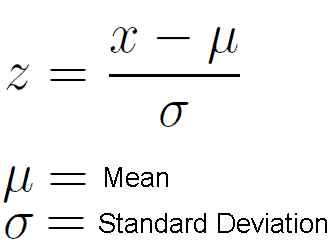

In [ ]:
# calculate std z score and beta z score and add to the table above

penalty = 10 # large number just to push the stocks down from getting used

std_weight = 0.3 # Can back test to see what's the ideal weighting if we have time
beta_weight = 0.7

std_z = (stock_stats["Std"] - stock_stats["Std"].mean()) / stock_stats["Std"].std()
beta_z = (stock_stats["Beta"] - stock_stats["Beta"].mean()) / stock_stats["Beta"].std()

# Combine z scores into a risk score in the dataframe
stock_stats["Risk Score"] = (std_weight * std_z) + (beta_weight * beta_z) + (penalty * stock_stats["Crashes"]) + (penalty * stock_stats["Small Cap"])

# Sort the dataframe, lower risk score is safer
stock_stats = stock_stats.sort_values("Risk Score")

# convert risk score sorted stocks into a list
ranked = stock_stats.index.tolist()

display(stock_stats)
display(ranked)

Step 4. Greedy picker:
greedy picker algorithm picks the next stock in the table that:
- reduces std by the most amount (given equal weight between current portfolio and the new stock)\
- starts by picking stocks with -ve risk score
- track a tally of number of stocks in each industry
- track a tally of all stocks in the portfolio
- If the stocks in total is still not enough, allow risk score to be +ve, but by small increments at a time to avoid allowing crazy stupid stocks like BB.TO <- i never wanna see this in my portfolio
- Stop when minimum number of stocks is met and also adding more increases std, so not necessarily all 20 stocks but will be near it, and will avoid taking high volatlity stocks with the highest risk scores


In [ ]:
# create combined_std, a function which calculates the std of an equal weighted portfolio given the list of its tickers, tickers
def combined_std(tickers):

    # every stock gets equal weight
    weights = 1 / len(tickers)

    returns = 0
    
    for tick in tickers:
        returns = returns + weights * daily_returns[tick]
        
    # return standard deviation of daily portfolio returns
    return returns.std(ddof=1)

In [ ]:
# dict to store running tally of number of stocks from each sector
sector_tally = {}

# max number of stocks per sector: for diversification
max_per_sector = int(sector_limit * min_stocks)  

# list to store selected stocks for portfolio
selected = []

# initialize tally for each sector so far
for tick in ranked:
    sector_tally[stock_stats.loc[tick, "Sector"]] = 0

# start with the safest stock in selected
selected.append(ranked[0])

# add 1 to its sector tally
sector_tally[stock_stats.loc[ranked[0], "Sector"]] = 1

# total number of stocks in portfolio
total_count = 1

# std of current portfolio to compare to
current_std = combined_std(selected)

# start by only allowing stocks with risk scores below -0.5, then if not enough, we'll increase threshold in increments and continue picking
score_limit = -0.5
score_step = 0.1

while total_count < max_stocks:
    # starting std of portfolio in current iteration (whatever stocks are in selected + the best stock found so far down the ranked list)
    best_tick = None
    best_std = None

    # loop through safe ranked stocks top down
    for tick in ranked:
        # skip any stocks already chosen for portfolio
        if tick in selected:
            continue

        # find the current stock's sector
        sector = stock_stats.loc[tick, "Sector"]
        # temporarily add 1 to that sector's tally for a check
        temp_tally = sector_tally[sector] + 1

        # if adding another stock from that sector goes over the limit, skip that stock
        if temp_tally > max_per_sector:
            continue

        # skip stocks where risk score is above the current limit
        if stock_stats.loc[tick, "Risk Score"] > score_limit:
            continue
            
        # calculate std if this stock were to be added to portfolio
        new_std = combined_std(selected + [tick])

        # skip the stock if the new std is worse
        if best_std is not None and new_std >= best_std:
            continue

        # if the stock passed all the tests
        best_tick = tick
        best_std = new_std

    # no stock fits requirements to be added to portfolio
    if best_tick is None:

        # if we're still under minimum num of stocks, raise the risk score by a little and continue picking stocks
        # check if we need more stocks, and that we haven't already maxed out our score limit (theoretically won't matter)
        if total_count < min_stocks and score_limit <= stock_stats["Risk Score"].max():
            score_limit += score_step
            continue
        break

    # otherwise: adding the stock lowers std, or we still need more stocks to reach the minimum
    selected.append(best_tick)
    sector_tally[stock_stats.loc[best_tick, "Sector"]] += 1
    total_count += 1
    current_std = best_std

print("Selected:", selected)
print("Total stocks:", total_count)
print("Stocks per sector:", sector_tally)
print("Equal-weight portfolio daily std:", current_std)

# NOTE THIS IS NOT THE SAME AS JUST TAKING TOP 20 STOCKS FROM RANKED LIST, IT INCLUDES SOME THAT ARE THERE CUZ OF PAIRED COVARIANCE BEING OPPOSITE LIKE AMAZON

Step 5. Weight Optimization:
- using iterative approach


In [ ]:
# Weight Optimization

# convert selected stock list into a series, alongside equal weight to each stock
initial_weights = pd.Series(1 / len(selected), index = selected)

# create a series, sectors, to store the stock name alongside its sector
sectors = {}
for tick in selected:
    sectors[tick] = stock_stats.loc[tick, "Sector"]

sectors = pd.Series(sectors)

# create a minimum weight each stock must conserve (cuz otherwise we might get stocks with 0% after giving away 1%, or just neglibible stocks that don't do anything)
# also, it's still good to hold some material weight in lower stocks for diversification

min_weight = 0.02

# from canada CPI, latest inflation rate
inflation = 0.031 

# calculating each stock's average year over year return, into a Series, for inflation comparison
yearly_returns = stock_stats.loc[selected, "Mean Return"] * 252

# will loop through the weight optimizer on 1 year periods, which occur every month
hold_days = 252 # roughly 1 year
start_every = 21 # roughly 1 trading month

def weighted_std(weights, period_prices): 
        shares = weights / period_prices.iloc[0] 
        values = (period_prices * shares).sum(axis=1)
        returns = values.pct_change().iloc[1:]
        return returns.std(ddof=1)

# function that will return the optimized weights for the current trading period being tested
def optimize_weights(period_prices):

    # For each stock try transferring 1% point to every other stock and keep the lowest std
    
    target_weights = initial_weights.copy() 
    step = 0.01  
    current_std = weighted_std(target_weights, period_prices)  
    move_history = [] 
    
    improved = True  
    while improved: 
        improved = False  # Assume no improvement at the beginning of each iteration
    
        for a in selected:  # Try each selected stock as the donor
            # skip the stock if donating x% puts it under the min weight requirement
            if target_weights[a] - step < min_weight:
                continue
        
            best_b = None  
            lowest_std = current_std  
    
            for b in selected:  
                if a == b:  
                    continue
    
                trial = target_weights.copy()  
                trial[a] -= step  
                trial[b] += step 
    
                if trial.max() > 0.15: 
                    continue
                if trial.groupby(sectors).sum().max() > 0.40:  
                    continue
                    # check restrictions

                # multiply stock weights by their yearly returns to get stock contribution to portfolio, add it all up to get portfolio return
                if (trial * yearly_returns).sum() < inflation:
                    continue
    
                trial_std = weighted_std(trial, period_prices)  # calculate portfolio risk after transfer
                if trial_std < lowest_std:
                    best_b = b
                    lowest_std = trial_std
    
            if best_b is not None:  
                target_weights[a] -= step
                target_weights[best_b] += step
                current_std = lowest_std
                move_history.append([a, best_b, current_std])  
                improved = True  

    return target_weights, current_std

# a list that stores the optimzied weights for each 1 year period tested
all_timelines = []
stds = []

# for each index in range, incremented by the period duration, goes upto len(aligned_prices) - hold_days because once it gets too close to len(aligned_prices), there isn't a year more of data to look at
for i in range(0, len(aligned_prices) - hold_days, start_every):
    selected_stocks_prices = aligned_prices[selected] # toss away price data for stocks we didn't select
    start_row = i # 0th index row
    end_row = i + hold_days # last row we want in the timeframe when running , 

    trading_window = selected_stocks_prices.iloc[start_row:(end_row + 1)] #note that iloc only includes (end_row - start_row number of rows) so we add 1
    
    weights, std = optimize_weights(trading_window)
    all_timelines.append(weights)
    stds.append(std)
    
# as of now, all_weights is a list containing Pandas series for each set of optimized weights from each period tested, attributed to each stock by name

# average the optimized weights found across all periods tested

print(f"Periods tested: {len(all_timelines)}")

# add up all the weights from every single series across all series, then divide each one by the number of series in total 
# i.e. avg the weights for each stock, to find ideal weighting
weights_B = sum(all_timelines) / len(all_timelines)

print(f"Average Optimzied Std: {np.mean(stds)}")  # average standard deviation after weight optimization

display(weights_B)

In [ ]:
#half_life = 100

In [ ]:
#def weighted_corr(t1, t2):
#    d1 = daily_returns[t1]
#    d2 = daily_returns[t2]
#    return d1.ewm(halflife=half_life).corr(d2).dropna().iloc[-1]

In [ ]:
#corr_mat = pd.DataFrame()
#
#for t1 in selected:
#    for t2 in selected:
#        corr_mat.loc[t1, t2] = weighted_corr(t1, t2)
#
#plain_corr = daily_returns[selected].corr()
#
#cov_mat = pd.DataFrame()
#
#for t1 in selected:
#    for t2 in selected:
#        cov_mat.loc[t1, t2] = plain_corr.loc[t1, t2] * daily_std[t1] * daily_std[t2]

In [ ]:
#display(corr_mat)
#display(cov_mat)

## Outputting Final Portfolios

In [ ]:
# send all data to function to create final dataframe
Portfolio_Final_B, fees_B, total_cost_B = final_table(weights_B.to_dict(), budget_B)

display(Portfolio_Final_B)

validate_portfolio(Portfolio_Final_B, fees_B, total_cost_B, budget_B)

### Client B — Financial justification


The below code is for generating the equal weight portfolio for the same stocks chosen

In [ ]:
def compare_equal_weight(weights):
    # Equal-weight Comparison
    
    # calculate the price growth factor for each stock
    prices = aligned_prices[weights.index] # store our portfolio's stocks into prices Series
    growth = prices.iloc[-1] / prices.iloc[0]
    
    equal_weights = pd.Series(1 / len(weights), index = weights.index)
    
    # calculate cumulative historical returns
    strategy_return = (growth * weights).sum() - 1
    equal_return = (growth * equal_weights).sum() - 1
    
    # calculate daily volatility
    strategy_std = weighted_std(weights, prices)
    equal_std = weighted_std(equal_weights, prices)
    
    # comparison table
    comparison = pd.DataFrame({
        "Historical Return (%)": [100 * strategy_return, 100 * equal_return],
        "Daily Std (%)": [100 * strategy_std, 100 * equal_std],
    }, index=["Optimized Portfolio", "Equal Weight Portfolio"])
    
    display(comparison.round(6))
    
    # produce the differences in percentage points
    print(f"Start Date: {prices.index[0].date()}")
    print(f"End Date: {prices.index[-1].date()}")
    print(f"Dates are inclusive")
    print(f"Daily Std change: {100 * (strategy_std - equal_std):+.4f} percentage points")
    print(f"Historical return change: {100 * (strategy_return - equal_return):+.4f} percentage points")

In [ ]:
compare_equal_weight(weights_B)

**Why does this portfolio make financial sense?** Explain how and why you select and weight stocks.

Our stock picking strategy follows these stages:

#### Stage 1 - Market Stats

**What it does:** We download data of the S&P 500 over the same period as our stock data. The index's closing prices stands in for the market, and is needed to calculate beta. 

The period we chose was: INSERT LATER
We specifically noted that including COVID-19 is okay since, weird market events or global shocks are normal and would occur in the future as well, so we want to whether the portfolio can maintain stability during these periods too. We also did not go too far back such that companies would no longer be similar businesses as what they are today, and any stocks missing past data is already filtered out (ADDDDDDDDDDDDDD THIS??????????????).

We chose the S&P500 since it is a very broad/diversified, market-cap-weighted index. It also represents the Canada and US markets overall pretty well (where all the stocks are coming from): while all S&P500 stocks are US-based, the US market makes up the majority of the equity value in these two countries, so it is a reasonable choice. 

#### Stage 2 - Statistics for every stock

**What it does:** For every eligible stock we calculate 4 statistics:
- Standard deviation of daily returns
- Beta of the stock's daily returns vs. market returns
- Crash count: how many times the stock fell by 20% in price within 5-week trading periods, over our data period
- Market cap: measured in CAD on the day trading starts

**Why these statistics:**

- Std: This is what the client uses to define risk, so we start with this calculation. However, since past std cannot reliably predict future stock volatility, we need to consider our other future-looking stats alongside this, and arguably more than std.
- Beta: While we can diversify our stocks to remove industry or business risk, this still would not remove market risk since all the stocks chosen are subject to shocks/volatility of the underlying market. So, to minimize the impacts of market risk, we focus on picking stocks with low beta (i.e. when the market moves in a direction, these stocks move less in that direction, compared to others). This is important for our client since they are buying and holding, so in a market downturn, they cannot exit their position, so we need our stock to minimize losses to maintain stability in this potential situation.
- Crash count: This is a future-looking statistic we created. While std already looks at volatility, we specifically want to capture company risks that sink value quickly. If a stock loses 20% in a week, which are often caused by company-specific new or shocks, like earnings reports, or certain CEOs getting caught in a honeypot, then it is possible that the same thing can happen again in the future. For instance, we wouldn't feel comfortable investing in Nvidia following it's honeypot saga, and following one crash, they had back to back surprises and weird announcements/events affecting the stock. We penalize these stocks, to avoid investing in them if possible.
- Market cap: Large and mature companies often have steady revenue streams, earnings, and are usually stabler than penny stocks. Specifically, we don't want to invest in a penny stock, startup, or similar company, that is simply stagnant or has low volume. On paper, these stocks may have low volatility, but truly they could go bankrupt or skyrocket in price in the future with little to no predicive ability. So, instead we focus on established businesses that are less likely to face such events. 

#### Stage 3 - Risk score ranking

**What it does:** Each stock is given a risk score, lower is safer.

> Risk score = 0.3 * (std z score) + 0.7 * (beta z-score) + 10 × (number of crashes) + 10 × (1 if market cap < $20B CAD)

Stocks are sorted from safest to riskiest.

**Why these choices:**

- Z-scores instead of raw values: since std and beta are measured differently and have different ranges (std is 0 to infinity, beta is -infinity to +infinity), we first standardize by converting std/beta values to a z-score (statistical comparison of how far the value is from the average of that measurement in the sample set). This standardization also lets us use z-score to compare whether an individual stock is more/less volatile than the average std at z-score = 0. It is calculated as follows:
> 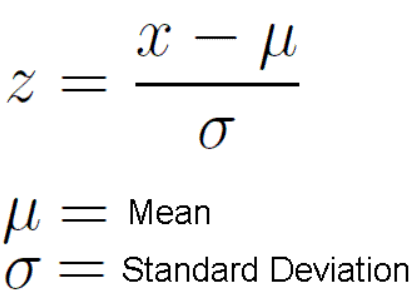
- Beta weighted more than std: at this stage, we are focusing on future-proofing our strategy against market downturns. We will focus more on std optimization in stages 4 and 5, on these forward-looking rankings of the stocks.
- Disproportionate penalties on stocks: The penalties are just arbitrarily large numbers to guarantee (most of the time) that a crashed or small-cap stock ranks way below the rest of the safer stocks, and will most likely be discluded from our ultimate portfolio. We only penalize the stocks, rather than dropping them from our list, in case future stages still need more stocks to meet minimum portfolio requirements (eg. 10 stock minimum), but these stay on only as a last resort.

#### Stage 4 - Stock selection algorithm

**What it does:** Starting from the lowest-risk stock, we repeatedly add the next stock that lowers std of the new combined portfolio the most. We start by only considering next stocks with a risk score below -0.5 (much safer than average). Only up to 4 stocks per sector may be chosen. If under these rules, fewer than 10 stocks are chosen, the risk score cutoff is loosened in steps of 0.1, to ensure penalized stocks are only a last resort, and safer stocks are considered first.

**Why these choices:**
- Choosing by portfolio std: std of a portfolio is not equal to the average of the stocks' individual std. It is actually less than this, which is the benefit of diversification, and this idea leads the whole picking process. The portfolio's volatility also depends on how stocks move together (eg. stock A zigs while stock B zags, because they are in contending industries). This effect can additionally lower portfolio std, and the picker captures these offsetting relationships that raw stat observations don't.
- Equal weighting combined portfolios: when judging stock picks, we compare the std of the combined equal-weighted portfolio chosen so far plus that candidate. As more stocks are added, the weight to each one in consideration decreases, and so at the beginning the picker favours stabler stocks, while later, it focuses more on how the stock behaves with the safer core other stocks (as described above). 
- # is there a formula for the above?
- Starting from lowest risk scored stock: as seen in class, adding a riskier stock to a stabler stock in a portfolio can raise the std of the overall portfolio, from the std of the stabler stock alone. To capture, and combat against this effect, we start off with a stock we consider very safe, and then build onto that portfolio with riskier stocks one at a time, each time choosing the next stock that keeps the portfolio's std lowest. Sometimes this increases or decreases the combined portfolio's std, which is compared to the previous safest alternative portfolio.
- Score cutoff of -0.5: Testing with the picker, we found that without a cutoff, it picks the riskiest stocks because they often offset the calmer ones. We still don't want to eagerly choose these risky stocks, so we restrict the picker to safer ones first, with safer ones still possibly offsetting each other. Gradually loosening it ensures at least 10 stocks are chosen.
- 4 stocks per sector: In the most restrictive case, we want at most 40% of 10 stocks in any sector. So this cap helps meet portfolio requirements (40% of 10 = 4). It also forces the portfolio to hold across industries and protect against sector-specific events/shocks (eg., regulation changes, outlook of an industry, etc.).  

#### Stage 5 - Weight optimization

**What it does:** Starting from equal weights, the optimizer tries moving 1% weight from one stock to another. It makes the shift if it lowers overall portfolio volatility, theoretically if it was held over a 1 year period in the past. It keeps on doing this until the weights minimize volatility, computing the optimal weights for that 1 year hold. Then, it shifts by 1 month, to consider a new 1 year period, and does the same thing. Throughout the process, each stock keeps at least 2% weight, no stock can exceed 15%, and no sector can exceed 40%. If the weight change makes the portfolio's annual return (average over our sample) less than inflation rate, it rejects that change. In the end, the average weights for each stock, as optimzied for every 1 year period, is computed, giving final weights.

**Why these choices:**
- Buy and hold: We emulate buying and holding portfolios in the past. Notably, this means weights of stocks would change in that portfolio as prices change. However, we want to consider this so that the weights chosen can... as time goes on, in a long-term future lens.
- Trying many 1-year periods: if we optimized for a single 1 year period, we would overfit to those events, and it would not reflect how the portfolio performs in the future, which has different events. Our strategy optimizes weights to work well across many different long-term periods.
- 2% minimum weight: Prevents weights that completely eradicate stocks, by giving meaningless weights near 0%, and overly relying on a few core stocks. Keeping some weighting in these stocks, rather than 0%, also helps maintain some diversification.
- Comparison to inflation rate: Client B wants to conserve as much money as possible, over a long period of time. If they just held completely unvolatile low growth stocks, which we try to achieve, they will still have a negative real rate of return, i.e. they lose money due to inflation over time. So if theoretically a portfolio with 0 volatility could be obtained, it still wouldn't help conserve the value of Client B's money, being as useless as cash at conserving it. So, we ensure that our weighted portfolio can beat inflation rate in our historical sample to increase the chance that it can do this in the future. In our tests we found that our portfolio anyways had really high nominal returns due to markets / large cap stocks performing well, so this may not make much of an impact. However, if a trul low volatility portfolio is achieved with new tickers, real returns should be kept positive.

- Comparison to equal weighted portfolio::::

**What evidence supports your strategy?** Discuss relevant statistics and the equal-weight comparison below.

**What could go wrong?** Identify at least one important limitation or situation in which this strategy may perform poorly.

- The past may not represent the future: all of our stats come from 1 period of past data, for simplification. For instance, the data does not include a full market crisis like 2008, which could be good for informing how this portfolio would perform in such a sever downturn, as our client wants a long-term portfolio and strategy. Our beta-based ranking can reduce this risk but cannot completely remove market risk.

- Concentration in sectors: Our portfolio in testing ended up with many stocks in consumer staples, healthcare, large banks, and telecom. These have historically been stable but share risks. #These stocks often pay dividends:? could that matter #hitting a sector here, ties to canadian economy, other markets, hit there very bad for portfolio

- Many of our holdings are US stocks, so their CAD value depends on the USD/CAD exchange rate. An increase in the Canadian dollar would lower the CAD value of these positions even if their US prices didn't change.

- Judgment: many parameters like the 0.3/0.7 weighting are judgment calls and not proven optimal values.

- Crash potential: a stock that has never crashed in the past still has the potential to do so in the future.

- Large cap volume: large-caps have higher volume and inherently more volatility on any trading day than a small-cap company does. While this increaes long-term / over-time stability, it may result in high short-term volatility, as shares trade hands more often.

- Equal weight selection: Our picker algorithm uses equal weights to decide stocks to combine into portfolio next. This may overlook stocks that can outperform others at a non-equal weight, or can deliver a better opposite directional benefit when weighted lower amount. But realistically, it would be really hard to implement dynamic weight considerations here, given portfolio restrctions and an unkown number of stocks we will have in the final portfolio.

## HIGH RETURNS PORTFOLIO:

Sharpe calculation

In [ ]:
# Add complete CBIL.TO data to cad_prices to create full_data

full_data = cad_prices.copy()

full_data["CBIL.TO"] = yf.download("CBIL.TO", period_start, period_end, auto_adjust=True)["Close"]

display(full_data.head())

In [ ]:
def get_stats(tick, half_life):
    s = full_data[tick].dropna()
    delta = np.log(1 + s.pct_change()).ewm(halflife = half_life)
    standard_deviation = delta.std().iloc[-1]
    average = delta.mean().iloc[-1]

    return average, standard_deviation

In [ ]:
Rf = get_stats("CBIL.TO", half_life)[0]
print("Risk free return:", Rf)

sharpe = {}

for tick in close_prices:
    stats = get_stats(tick, half_life)
    sharpe[tick] = (stats[0] - Rf)/stats[1]

sharpe = dict(sorted(sharpe.items(), key = lambda item:item[1]))
print(sharpe)

### Client A — Financial justification


The below code is for generating the equal weight portfolio for the same stocks chosen

In [ ]:
weights_A = None
compare_equal_weight(weights_A)